# 00 - Khảo sát PlantVillage

Notebook này ghi nhận kích thước dữ liệu, phân bố lớp, ảnh mẫu và các kiểm tra chất lượng trước khi chia dữ liệu.

In [1]:
!pip install metadata
!pip install matplotlib
!pip install seaborn

  Using cached metadata-0.2.tar.gz (1.5 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached metadata-0.1.1.tar.gz (1.5 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
INFO: pip is looking at multiple versions of metadata to determine which version is compatible with other requirements. This could take a while.
  Using cached metadata-0.1.tar.gz (1.1 kB)
  Installing build dependencies: started
  Installing build d

ERROR: Cannot install metadata==0.1, metadata==0.1.1 and metadata==0.2 because these package versions have conflicting dependencies.
ERROR: ResolutionImpossible: for help visit https://pip.pypa.io/en/latest/topics/dependency-resolution/#dealing-with-dependency-conflicts


In [6]:
from pathlib import Path
import sys
import hashlib

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from PIL import Image, UnidentifiedImageError

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.data import discover_images

DATA_ROOT = PROJECT_ROOT.parent / 'PlantVillage-Dataset-master' / 'PlantVillage-Dataset-master' / 'raw' / 'color'
metadata = discover_images(DATA_ROOT)
eda = metadata.copy()
eda[['plant', 'condition']] = eda['class_name'].str.split('___', n=1, expand=True)
eda['health_status'] = eda['condition'].str.lower().eq('healthy').map({True: 'Khỏe', False: 'Bệnh'})
eda['file_extension'] = eda['path'].map(lambda p: Path(p).suffix.lower())
eda['file_size_mb'] = eda['path'].map(lambda p: Path(p).stat().st_size / 1024**2)

print(f'DATA_ROOT: {DATA_ROOT}')
print(f'Tong so anh: {len(metadata):,}')
print(f'Tong so lop: {metadata["class_name"].nunique()}')
print(f'Tong dung luong: {sum(Path(p).stat().st_size for p in metadata["path"] if Path(p).exists()) / 1024**2:.2f} MB')
metadata.head()

DATA_ROOT: c:\Users\kelac\Downloads\HOCTAP\deeplearning\deeplearning cuoiky\DUAN\PlantVillage-Dataset-master\PlantVillage-Dataset-master\raw\color
Tong so anh: 54,305
Tong so lop: 38
Tong dung luong: 811.37 MB


,path,class_name,label
0,C:\Users\kelac\Downloads\HOCTAP\deeplearning\d...,Apple___Apple_scab,0
1,C:\Users\kelac\Downloads\HOCTAP\deeplearning\d...,Apple___Apple_scab,0
2,C:\Users\kelac\Downloads\HOCTAP\deeplearning\d...,Apple___Apple_scab,0
3,C:\Users\kelac\Downloads\HOCTAP\deeplearning\d...,Apple___Apple_scab,0
4,C:\Users\kelac\Downloads\HOCTAP\deeplearning\d...,Apple___Apple_scab,0


## 1. Tổng quan dữ liệu

Mục tiêu của phần này là kiểm tra quy mô, cấu trúc nhãn và mức cân bằng của dữ liệu trước khi huấn luyện.

#### Khai thác tên lớp
Tên lớp có định dạng `Loai_cay___Tinh_trang_benh`. Việc tách riêng hai thành phần giúp kiểm tra phân bố theo cây và theo tình trạng sức khỏe.

In [13]:
eda = metadata.copy()
eda[['plant', 'condition']] = eda['class_name'].str.split('___', n=1, expand=True)
eda['health_status'] = eda['condition'].str.lower().eq('healthy').map({True: 'Khỏe', False: 'Bệnh'})
eda['file_extension'] = eda['path'].map(lambda p: Path(p).suffix.lower())
eda['file_size_mb'] = eda['path'].map(lambda p: Path(p).stat().st_size / 1024**2)

print('Kiem tra du lieu trung lap va gia tri thieu')
print(eda[['path', 'class_name', 'label', 'plant', 'condition']].isna().sum())
print('Duong dan trung lap:', eda['path'].duplicated().sum())

basic_summary = pd.DataFrame({
    'Chi so': ['Tong so anh', 'So lop', 'So loai cay', 'Lop it anh nhat', 'Lop nhieu anh nhat', 'Dung luong trung binh'],
    'Gia tri': [
        len(eda), eda['class_name'].nunique(), eda['plant'].nunique(),
        eda['class_name'].value_counts().min(), eda['class_name'].value_counts().max(),
        f'{eda["file_size_mb"].mean():.3f} MB'
    ]
})
display(basic_summary)

display(eda['file_extension'].value_counts().rename('So anh').to_frame())

Kiem tra du lieu trung lap va gia tri thieu
path          0
class_name    0
label         0
plant         0
condition     0
dtype: int64
Duong dan trung lap: 0


,Chi so,Gia tri
0,Tong so anh,54305
1,So lop,38
2,So loai cay,14
3,Lop it anh nhat,152
4,Lop nhieu anh nhat,5507
5,Dung luong trung binh,0.015 MB


,So anh
file_extension,
.jpg,54303
.png,1
.jpeg,1


## 2. Phân bố lớp và mức cân bằng

Mức cân bằng ảnh hưởng trực tiếp tới Macro-F1. Ta xem số ảnh mỗi lớp, tỷ lệ phần trăm, lớp thiếu dữ liệu tương đối và thống kê cây khỏe/bệnh.

,so_anh,ty_le_%,nho_hon_trung_binh
class_name,,,
Orange___Haunglongbing_(Citrus_greening),5507,10.14,False
Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357,9.86,False
Soybean___healthy,5090,9.37,False
Peach___Bacterial_spot,2297,4.23,False
Tomato___Bacterial_spot,2127,3.92,False
Tomato___Late_blight,1909,3.52,False
Squash___Powdery_mildew,1835,3.38,False
Tomato___Septoria_leaf_spot,1771,3.26,False
Tomato___Spider_mites Two-spotted_spider_mite,1676,3.09,False


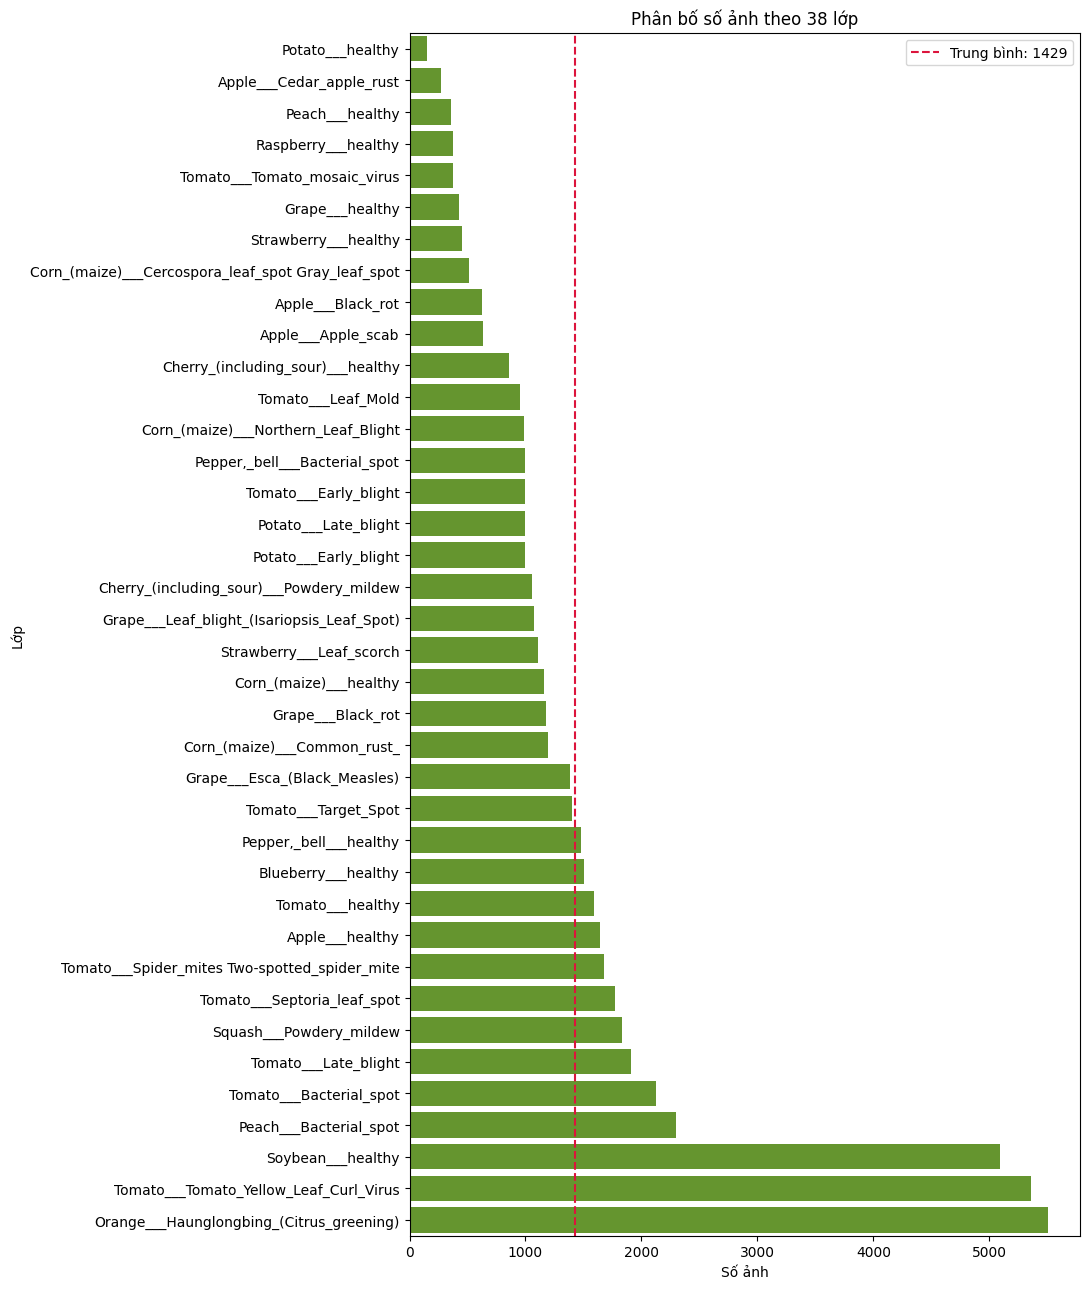

health_status,Bệnh,Khỏe,tong,ty_le_khoe_%
plant,,,,
Tomato,16569,1591,18160,8.8
Orange,5507,0,5507,0.0
Soybean,0,5090,5090,100.0
Grape,3639,423,4062,10.4
Corn_(maize),2690,1162,3852,30.2
Apple,1526,1645,3171,51.9
Peach,2297,360,2657,13.5
"Pepper,_bell",997,1478,2475,59.7
Potato,2000,152,2152,7.1


In [14]:
class_balance = eda['class_name'].value_counts().rename('so_anh').to_frame()
class_balance['ty_le_%'] = (class_balance['so_anh'] / len(eda) * 100).round(2)
class_balance['nho_hon_trung_binh'] = class_balance['so_anh'] < eda['class_name'].value_counts().mean()
display(class_balance)

counts = eda['class_name'].value_counts().sort_values()
plt.figure(figsize=(11, 13))
sns.barplot(x=counts.values, y=counts.index, color='#66a61e')
plt.axvline(counts.mean(), color='crimson', linestyle='--', label=f'Trung bình: {counts.mean():.0f}')
plt.title('Phân bố số ảnh theo 38 lớp')
plt.xlabel('Số ảnh'); plt.ylabel('Lớp')
plt.legend()
plt.tight_layout()
plt.show()

health_counts = eda.groupby(['plant', 'health_status']).size().unstack(fill_value=0)
health_counts['tong'] = health_counts.sum(axis=1)
health_counts['ty_le_khoe_%'] = (health_counts['Khỏe'] / health_counts['tong'] * 100).round(1)
display(health_counts.sort_values('tong', ascending=False))

## 3. Quan sát ảnh mẫu

Mỗi lớp được lấy ngẫu nhiên một ảnh để quan sát chất lượng, nền, góc chụp và sự khác biệt hình thái giữa các bệnh.

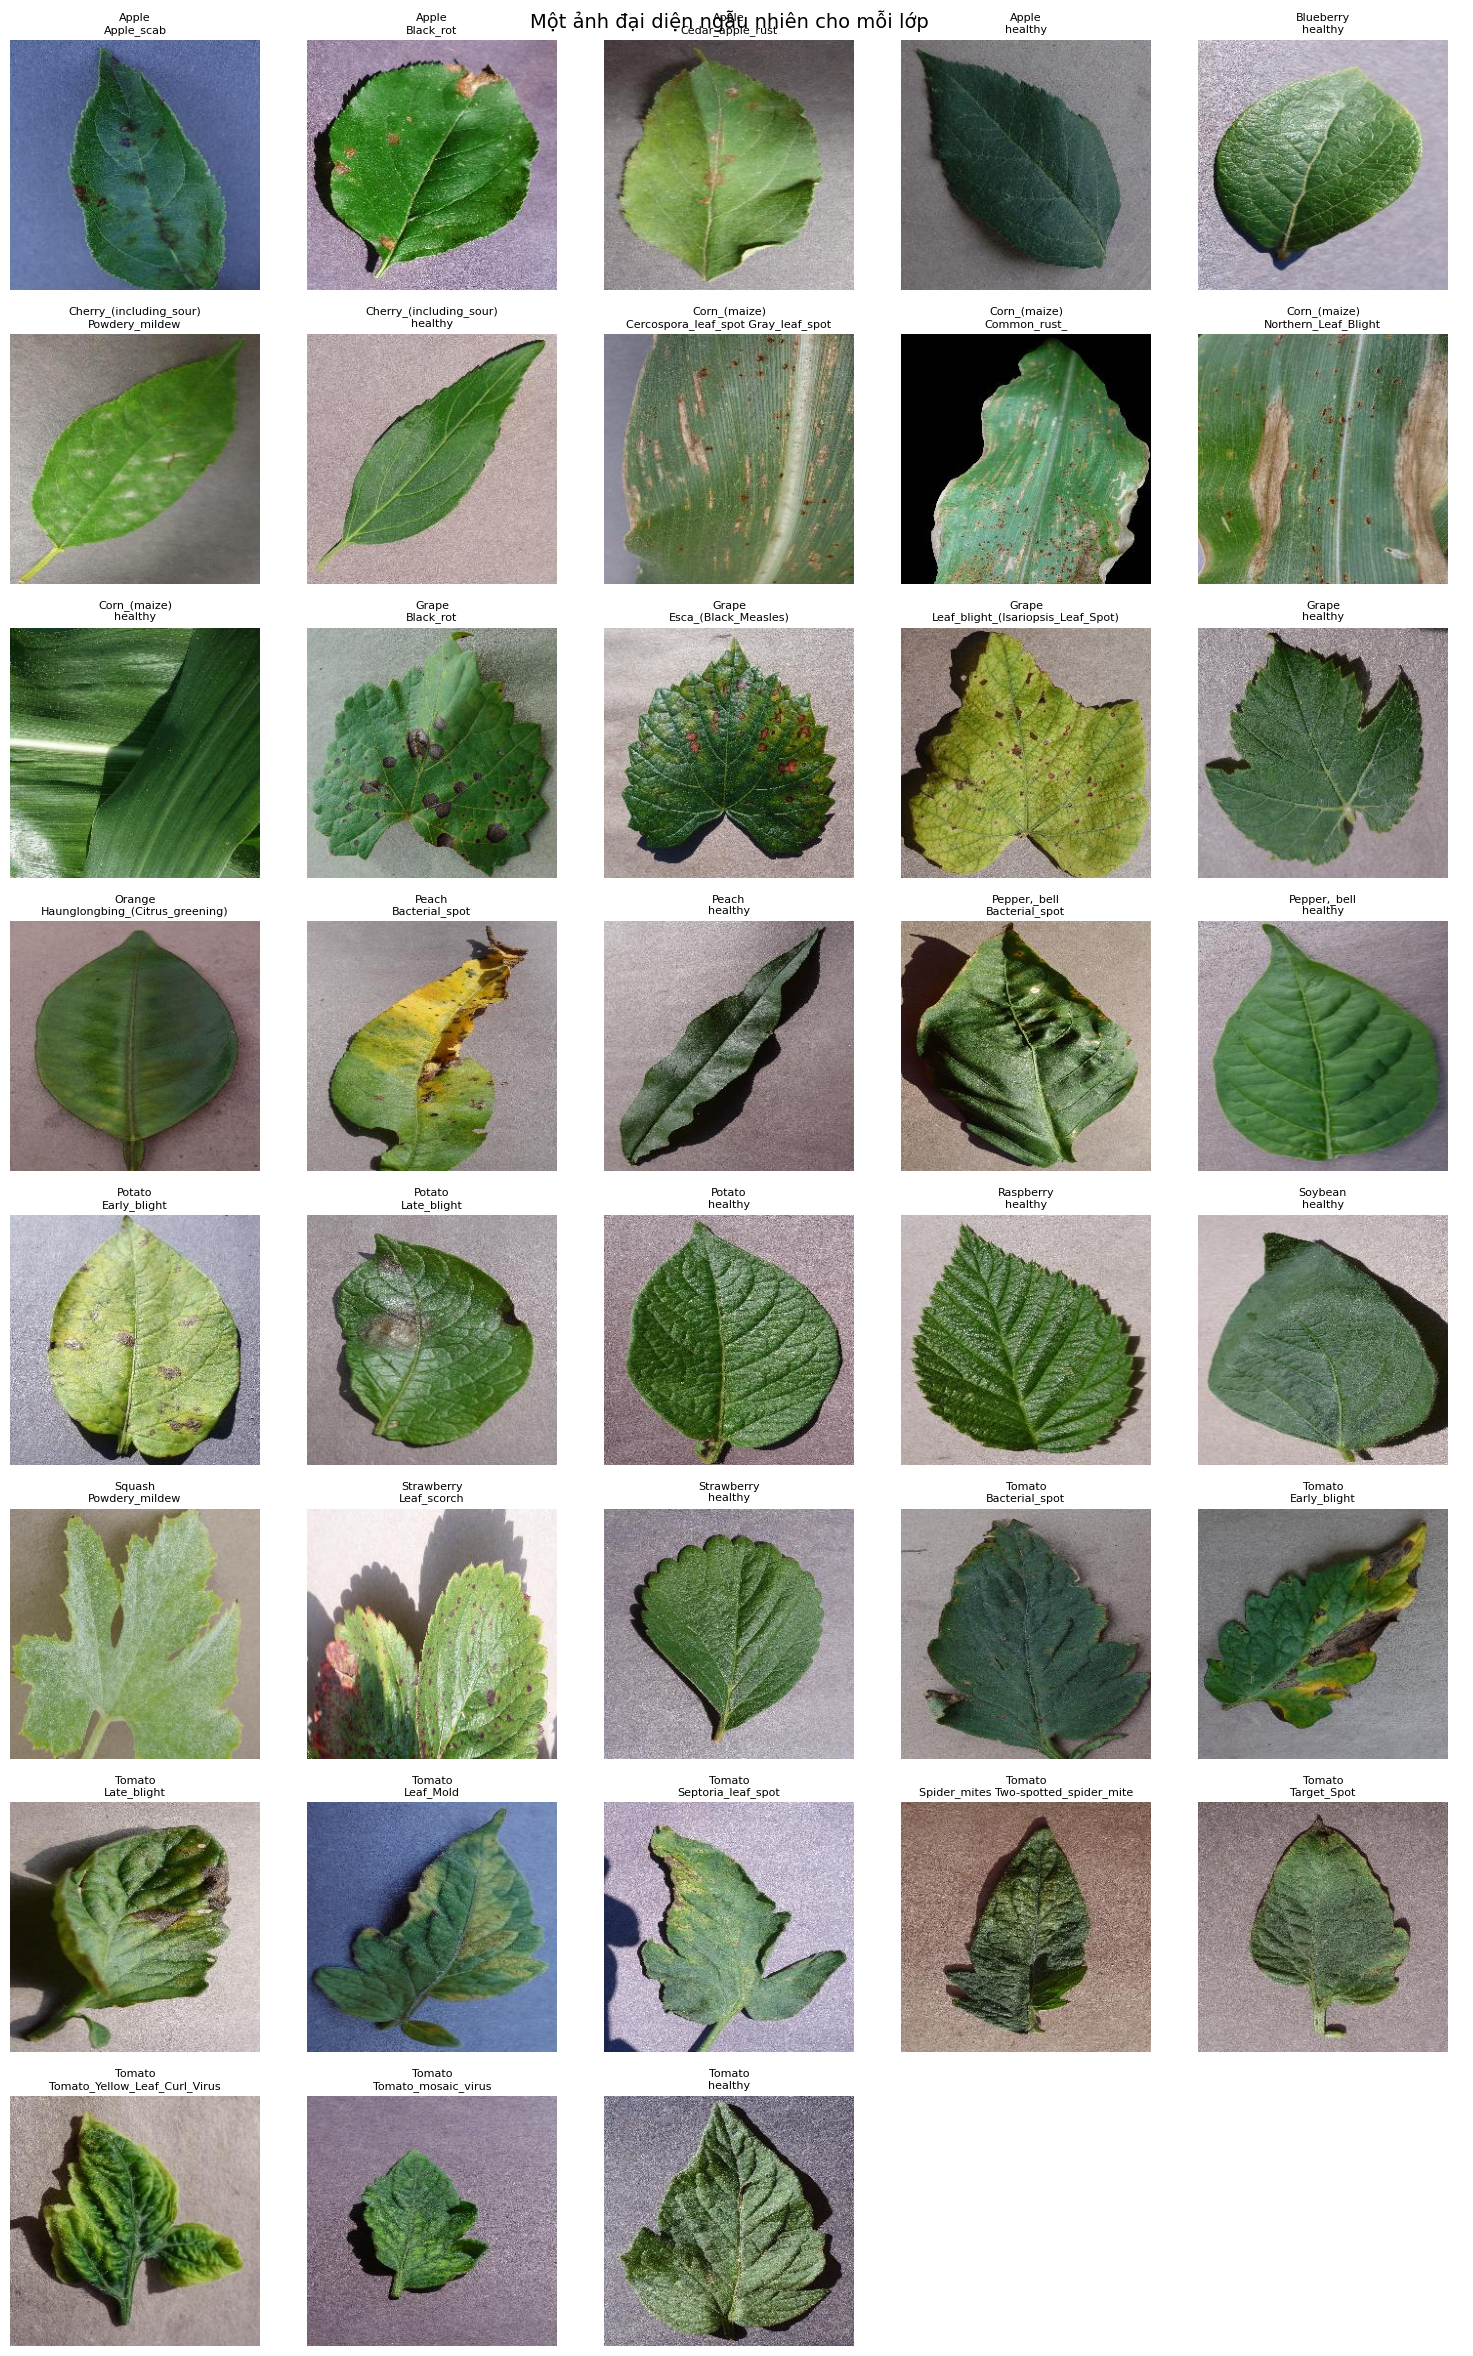

In [15]:
rng = np.random.default_rng(42)
classes = sorted(eda['class_name'].unique())
cols = 5
rows = int(np.ceil(len(classes) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(15, 3 * rows))
axes = np.array(axes).reshape(-1)

for ax, class_name in zip(axes, classes):
    candidates = eda.loc[eda['class_name'].eq(class_name), 'path'].tolist()
    image_path = candidates[rng.integers(len(candidates))]
    with Image.open(image_path) as im:
        ax.imshow(im.convert('RGB'))
    ax.set_title(class_name.replace('___', '\n'), fontsize=8)
    ax.axis('off')

for ax in axes[len(classes):]:
    ax.axis('off')
plt.suptitle('Một ảnh đại diện ngẫu nhiên cho mỗi lớp', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Kiểm tra chất lượng ảnh

Kiểm tra: ảnh hỏng, mode, kích thước, tỷ lệ khung hình, kích thước byte và trùng lặp nội dung sau khi chuẩn hóa về 64x64 RGB.

In [16]:
quality_rows = []
corrupt_paths = []
normalized_hashes = []

for path in eda['path']:
    try:
        with Image.open(path) as image:
            image.load()
            width, height = image.size
            mode = image.mode
            normalized = image.convert('RGB').resize((64, 64), Image.Resampling.BILINEAR)
            pixel_hash = hashlib.md5(normalized.tobytes()).hexdigest()
        normalized_hashes.append(pixel_hash)
        quality_rows.append({'width': width, 'height': height, 'mode': mode,
                             'aspect_ratio': width / height,
                             'file_size_kb': Path(path).stat().st_size / 1024,
                             'normalized_hash': pixel_hash})
    except (UnidentifiedImageError, OSError, ValueError):
        corrupt_paths.append(path)
        normalized_hashes.append(None)
        quality_rows.append({'width': np.nan, 'height': np.nan, 'mode': 'CORRUPT',
                             'aspect_ratio': np.nan, 'file_size_kb': np.nan,
                             'normalized_hash': None})

quality = pd.DataFrame(quality_rows)
eda = pd.concat([eda.reset_index(drop=True), quality], axis=1)

print(f'Anh hỏng hoặc không đọc được: {len(corrupt_paths):,}')
if corrupt_paths:
    display(pd.DataFrame({'duong_dan': corrupt_paths}))

print('Thong ke kich thuoc')
display(eda[['width', 'height', 'aspect_ratio', 'file_size_kb']].describe().round(2))
print('Mode anh')
display(eda['mode'].value_counts().rename('so_anh').to_frame())

duplicate_rows = eda[eda['normalized_hash'].notna() & eda['normalized_hash'].duplicated(keep=False)]
print(f'So anh tham gia nhom trùng ảnh sau chuẩn hóa: {len(duplicate_rows):,}')
print(f'So nhom anh trùng: {duplicate_rows["normalized_hash"].nunique()}')

Anh hỏng hoặc không đọc được: 0
Thong ke kich thuoc


,width,height,aspect_ratio,file_size_kb
count,54305.0,54305.0,54305.0,54305.00
mean,256.0,256.0,1.0,15.30
std,0.0,0.0,0.0,4.32
min,256.0,256.0,1.0,3.36
25%,256.0,256.0,1.0,11.99
50%,256.0,256.0,1.0,15.58
75%,256.0,256.0,1.0,18.60
max,256.0,256.0,1.0,118.80


Mode anh


,so_anh
mode,
RGB,54304
RGBA,1


So anh tham gia nhom trùng ảnh sau chuẩn hóa: 42
So nhom anh trùng: 21


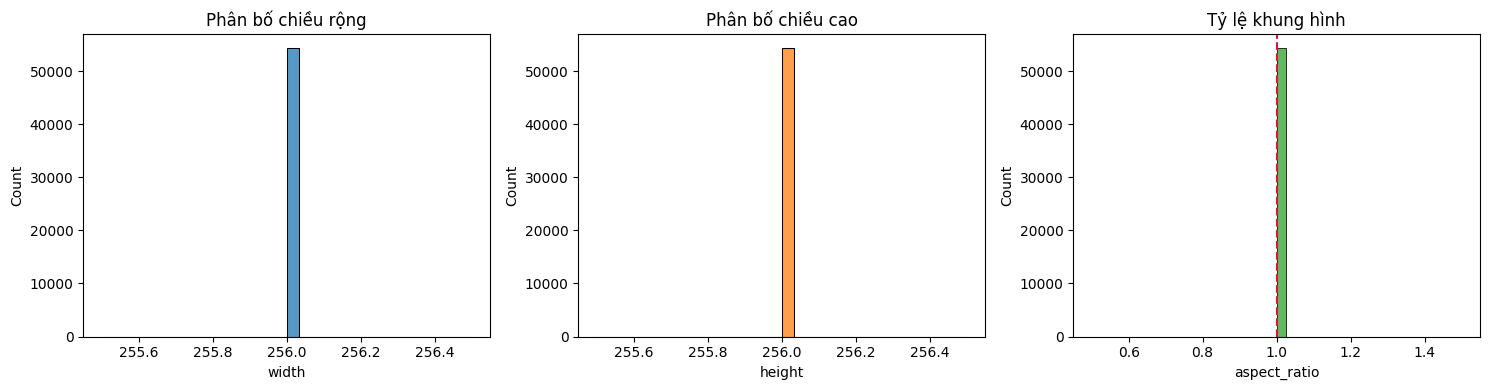

Các kích thước phổ biến nhất


,,so_anh
width,height,
256,256,54305


Nhom trùng xuất hiện ở nhiều lop: 0


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(eda['width'].dropna(), bins=30, ax=axes[0], color='#1f77b4')
axes[0].set_title('Phân bố chiều rộng')
sns.histplot(eda['height'].dropna(), bins=30, ax=axes[1], color='#ff7f0e')
axes[1].set_title('Phân bố chiều cao')
sns.histplot(eda['aspect_ratio'].dropna(), bins=40, ax=axes[2], color='#2ca02c')
axes[2].axvline(1, color='crimson', linestyle='--')
axes[2].set_title('Tỷ lệ khung hình')
plt.tight_layout()
plt.show()

print('Các kích thước phổ biến nhất')
display(eda.groupby(['width', 'height']).size().sort_values(ascending=False).head(15).rename('so_anh').to_frame())

cross_class_duplicates = (
    eda.groupby('normalized_hash')['class_name'].nunique()
    .loc[lambda s: s > 1]
)
print(f'Nhom trùng xuất hiện ở nhiều lop: {len(cross_class_duplicates)}')

## 5. Phân tích thống kê màu và độ sáng

Phân tích mẫu đại diện để đánh giá tông nền, độ tương phản và xu hướng lấy mẫu. Kết quả là tín hiệu hỗ trợ augmentation chứ không thay thế kiểm tra toàn bộ ảnh thủ công.

brightness              contrast       
                               mean        std       mean    std
plant                                                           
Apple                    112.099998  17.230000  43.250000   9.94
Blueberry                136.529999  16.530001  60.630001   5.44
Cherry_(including_sour)  124.879997  17.500000  42.150002   7.45
Corn_(maize)             113.610001  26.790001  46.369999  13.56
Grape                    120.290001  12.410000  52.730000   7.57
Orange                    98.669998  17.160000  43.320000   9.38
Peach                    120.680000  13.840000  46.700001   7.30
Pepper,_bell             118.110001  15.790000  53.700001   8.10
Potato                   122.690002  12.400000  48.099998   6.58
Raspberry                121.800003   9.530000  56.299999   5.62
Soybean                  132.100006  16.030001  50.959999   4.26
Squash                   119.889999   9.300000  34.849998   4.60
Strawberry               129.410004  12.760000  51.540001   5.75
Tomato                   113.320000  15.170000  43.310001   9.62

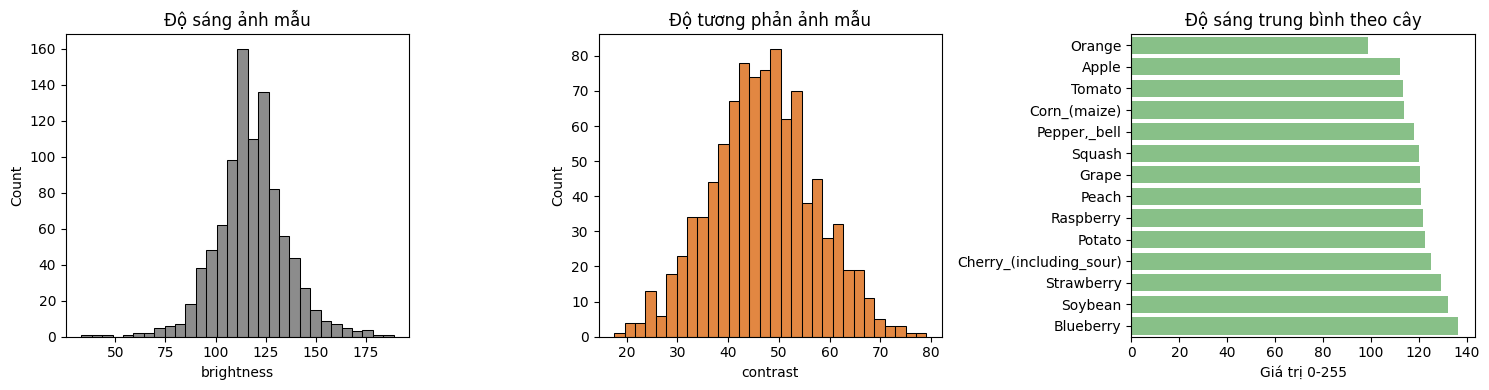

In [10]:
sampled = eda.groupby('class_name', group_keys=False).sample(n=25, random_state=42)
color_stats = []

for row in sampled.itertuples():
    with Image.open(row.path) as image:
        rgb = np.asarray(image.convert('RGB'), dtype=np.float32)
    color_stats.append({
        'class_name': row.class_name,
        'plant': row.plant,
        'mean_red': rgb[:, :, 0].mean(),
        'mean_green': rgb[:, :, 1].mean(),
        'mean_blue': rgb[:, :, 2].mean(),
        'brightness': rgb.mean(),
        'contrast': rgb.std(),
    })

color_stats = pd.DataFrame(color_stats)
display(color_stats.groupby(['plant']).agg({'brightness': ['mean', 'std'], 'contrast': ['mean', 'std']}).round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(color_stats['brightness'], bins=30, ax=axes[0], color='#666666')
axes[0].set_title('Độ sáng ảnh mẫu')
sns.histplot(color_stats['contrast'], bins=30, ax=axes[1], color='#d95f02')
axes[1].set_title('Độ tương phản ảnh mẫu')
class_brightness = color_stats.groupby('plant')['brightness'].mean().sort_values()
sns.barplot(x=class_brightness.values, y=class_brightness.index, ax=axes[2], color='#7fc97f')
axes[2].set_title('Độ sáng trung bình theo cây')
axes[2].set_xlabel('Giá trị 0-255'); axes[2].set_ylabel('')
plt.tight_layout()
plt.show()

## 6. Mô phỏng split và rò rỉ dữ liệu

Dùng chiến lược phân tầng seed=42 với 70% train, 15% validation và 15% test. Sau split, kiểm tra cả tỷ lệ lớp lẫn các ảnh trùng xuất hiện trong nhiều tập.

In [11]:
from src.data import stratified_split

split_preview = stratified_split(metadata, seed=42, val_size=0.15, test_size=0.15)
split_preview = split_preview.merge(
    eda[['path', 'normalized_hash']], on='path', how='left'
)

print('Phan bo tap')
display(split_preview['split'].value_counts().rename('so_anh').to_frame())

split_class = pd.crosstab(split_preview['class_name'], split_preview['split'])
split_class['chenh_train_test_%'] = (
    (split_class.get('train', 0) / split_preview['split'].eq('train').sum() -
     split_class.get('test', 0) / split_preview['split'].eq('test').sum()) * 100
).abs().round(2)
display(split_class.sort_values('chenh_train_test_%', ascending=False).head(10))

same_hash_splits = (
    split_preview.dropna(subset=['normalized_hash'])
    .groupby('normalized_hash')['split']
    .nunique()
)
print(f'Nhóm trùng xuất hiện trong nhiều split: {(same_hash_splits > 1).sum()}')

Phan bo tap


,so_anh
split,
train,38013
test,8146
val,8146


split,test,train,val,chenh_train_test_%
class_name,,,,
Apple___Apple_scab,94,441,95,0.01
Grape___healthy,63,296,64,0.01
Tomato___Tomato_Yellow_Leaf_Curl_Virus,804,3749,804,0.01
Tomato___Target_Spot,211,982,211,0.01
Tomato___Spider_mites Two-spotted_spider_mite,251,1174,251,0.01
Tomato___Septoria_leaf_spot,266,1239,266,0.01
Tomato___Late_blight,286,1337,286,0.01
Strawberry___healthy,68,320,68,0.01
Strawberry___Leaf_scorch,166,777,166,0.01


Nhóm trùng xuất hiện trong nhiều split: 13


## 7. Kết luận và quyết định tiền xử lý

Kết quả thực nghiệm từ notebook:

- Dataset có 54.305 ảnh hợp lệ, không phát hiện ảnh hỏng.
- Tất cả ảnh đều 256×256; 54.304 ảnh là RGB và 1 ảnh là RGBA. PIL và PyTorch cần chuẩn hóa mọi ảnh sang RGB.
- Có 21 nhóm trùng sau chuẩn hóa 64×64 RGB, gồm 42 ảnh tham gia; 13 nhóm trùng nằm ở nhiều split trong mô phỏng seed=42.
- Trước huấn luyện, cần loại trùng toàn cục hoặc gộp nhóm trùng vào cùng một split để tránh rò rỉ dữ liệu.
- Split seed=42 tạo 38.013 train, 8.146 validation và 8.146 test; tỷ lệ lớp giữa train/test là tương đối ổn định.
- Kích thước cố định 256×256 cho phép resize trực tiếp hoặc tiếp tục resize về 224×224 cho ResNet-18.
- Macro-F1 vẫn cần làm metric chính; weighted loss hoặc weighted sampler có thể xem xét nếu phân tích cân bằng cho thấy sai lệch rõ.
- Augmentation nên giữ chặt, biến đổi vừa phải về flip, rotation và color jitter để tránh làm méo đặc trưng lá.

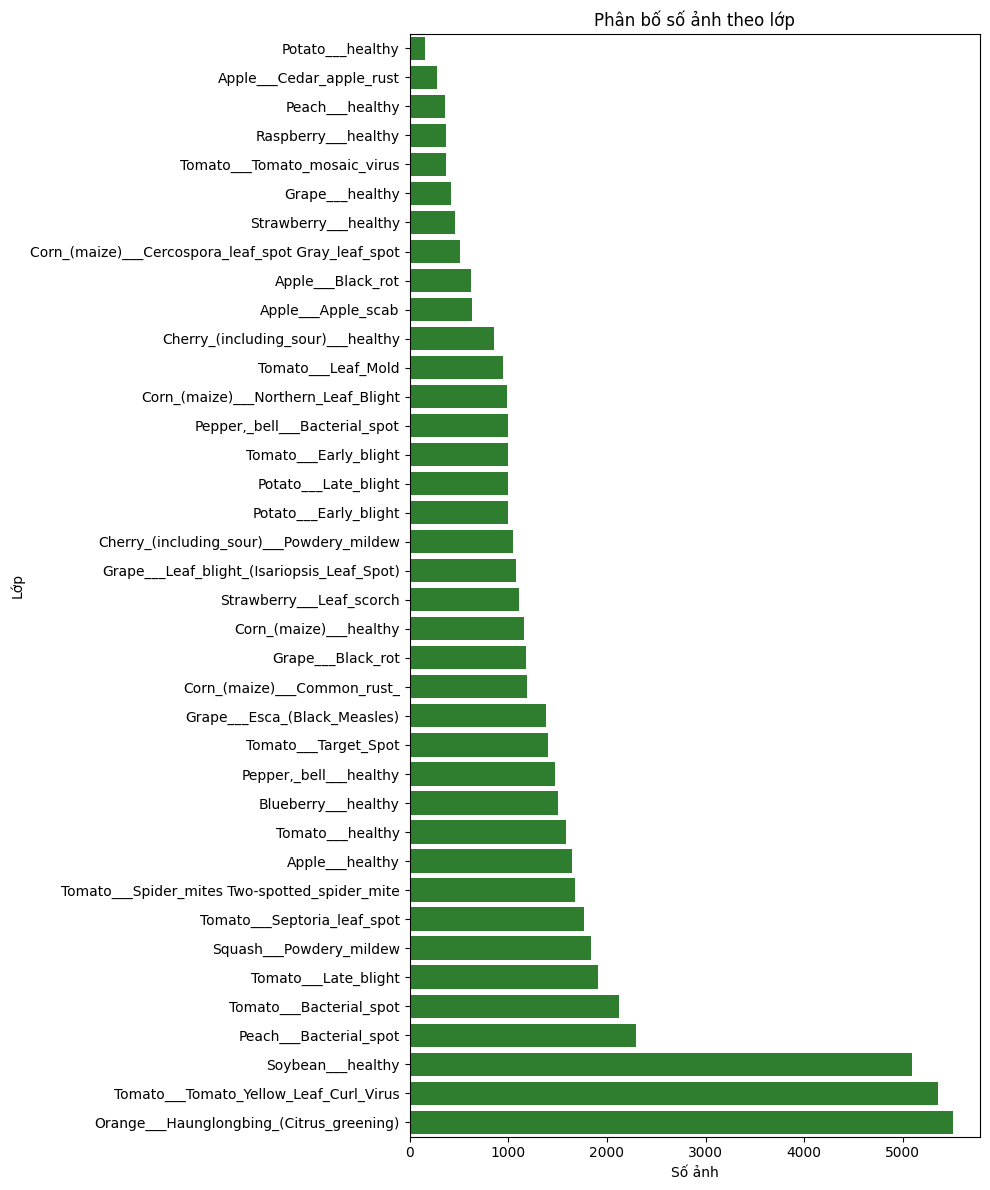

In [2]:
counts = metadata['class_name'].value_counts().sort_values()
plt.figure(figsize=(10, 12))
sns.barplot(x=counts.values, y=counts.index, color='forestgreen')
plt.title('Phân bố số ảnh theo lớp')
plt.xlabel('Số ảnh'); plt.ylabel('Lớp')
plt.tight_layout()
plt.show()

TONG QUAN DATASET


,Chi so,Gia tri
0,Tong so anh,54305
1,Tong so loai cay,14
2,Tong so lop phan loai,38
3,So loai cay co anh khoe,12
4,So loai cay co anh benh,11
5,So lop khoe,12
6,So lop benh,26


CHI TIET THEO TUNG LOAI CAY


,so_lop_khoe,so_lop_benh,so_anh_khoe,so_anh_benh,tong_so_anh
plant,,,,,
Tomato,1,9,1591,16569,18160
Orange,0,1,0,5507,5507
Soybean,1,0,5090,0,5090
Grape,1,3,423,3639,4062
Corn_(maize),1,3,1162,2690,3852
Apple,1,3,1645,1526,3171
Peach,1,1,360,2297,2657
"Pepper,_bell",1,1,1478,997,2475
Potato,1,2,152,2000,2152


health_status,cac_lop_benh,cac_lop_khoe
plant,,
Apple,"Apple_scab, Black_rot, Cedar_apple_rust",healthy
Blueberry,Khong co,healthy
Cherry_(including_sour),Powdery_mildew,healthy
Corn_(maize),"Cercospora_leaf_spot Gray_leaf_spot, Common_ru...",healthy
Grape,"Black_rot, Esca_(Black_Measles), Leaf_blight_(...",healthy
Orange,Haunglongbing_(Citrus_greening),Khong co
Peach,Bacterial_spot,healthy
"Pepper,_bell",Bacterial_spot,healthy
Potato,"Early_blight, Late_blight",healthy


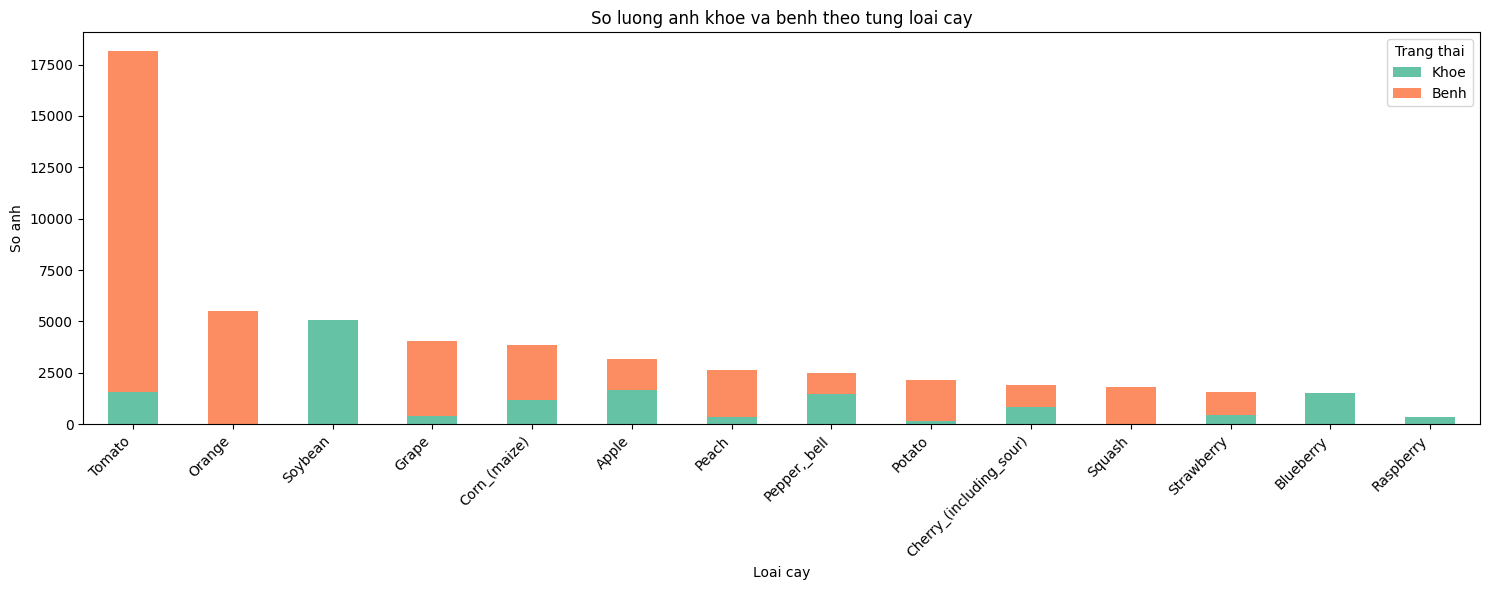

In [12]:
# Phan tich chi tiet theo loai cay va trang thai suc khoe
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.data import discover_images

DATA_ROOT = PROJECT_ROOT.parent / 'PlantVillage-Dataset-master' / 'PlantVillage-Dataset-master' / 'raw' / 'color'
metadata = discover_images(DATA_ROOT)

analysis = metadata.copy()
analysis[['plant', 'condition']] = analysis['class_name'].str.split('___', n=1, expand=True)
analysis['health_status'] = analysis['condition'].str.lower().eq('healthy').map({True: 'Khoe', False: 'Benh'})

summary = pd.DataFrame({
    'Chi so': [
        'Tong so anh', 'Tong so loai cay', 'Tong so lop phan loai',
        'So loai cay co anh khoe', 'So loai cay co anh benh',
        'So lop khoe', 'So lop benh',
    ],
    'Gia tri': [
        len(analysis),
        analysis['plant'].nunique(),
        analysis['class_name'].nunique(),
        analysis.loc[analysis['health_status'].eq('Khoe'), 'plant'].nunique(),
        analysis.loc[analysis['health_status'].eq('Benh'), 'plant'].nunique(),
        analysis.loc[analysis['health_status'].eq('Khoe'), 'class_name'].nunique(),
        analysis.loc[analysis['health_status'].eq('Benh'), 'class_name'].nunique(),
    ],
})
print('TONG QUAN DATASET')
display(summary)

class_counts = (
    analysis.groupby(['plant', 'health_status'])['class_name'].nunique()
    .unstack(fill_value=0)
    .reindex(columns=['Khoe', 'Benh'], fill_value=0)
)
image_counts = (
    analysis.groupby(['plant', 'health_status']).size()
    .unstack(fill_value=0)
    .reindex(columns=['Khoe', 'Benh'], fill_value=0)
)

plant_summary = pd.DataFrame({
    'so_lop_khoe': class_counts['Khoe'],
    'so_lop_benh': class_counts['Benh'],
    'so_anh_khoe': image_counts['Khoe'],
    'so_anh_benh': image_counts['Benh'],
})
plant_summary['tong_so_anh'] = plant_summary['so_anh_khoe'] + plant_summary['so_anh_benh']
plant_summary = plant_summary.sort_values('tong_so_anh', ascending=False)

print('CHI TIET THEO TUNG LOAI CAY')
display(plant_summary)

class_detail = (
    analysis.groupby(['plant', 'health_status'])['condition']
    .agg(lambda values: ', '.join(sorted(values.unique())))
    .unstack(fill_value='Khong co')
    .rename(columns={'Khoe': 'cac_lop_khoe', 'Benh': 'cac_lop_benh'})
)
display(class_detail)

plot_data = plant_summary[['so_anh_khoe', 'so_anh_benh']].rename(
    columns={'so_anh_khoe': 'Khoe', 'so_anh_benh': 'Benh'}
)
plot_data.plot(kind='bar', stacked=True, figsize=(15, 6), color=['#66c2a5', '#fc8d62'])
plt.title('So luong anh khoe va benh theo tung loai cay')
plt.xlabel('Loai cay')
plt.ylabel('So anh')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Trang thai')
plt.tight_layout()
plt.show()
